# Figure 4: SMILES versus CCD, split at each model's training cutoff

PXR and CYP3A4 structures (five seeds) split into "before" (released on or before the cutoff, so the structure could have been seen in training) and "after" (released after it).

Cutoffs: Boltz-2 2023-06-01; AlphaFold3 and OF3 p2 2021-09-30. OBv0 (2025-06-30) is not split: its cutoff falls after nearly every structure. Groups with fewer than 5 structures are dropped.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "src"))   # run from notebooks/
import common as C

In [2]:
B = C.load_poses()
CUT_NOTE = {"boltz2": "2023-06-01", "af3": "2021-09-30", "of3": "2021-09-30"}


def groups(model):
    """(target, side) -> SMILES/CCD stats for the structures before / after the model's cutoff."""
    out = {}
    for t, name in (("pxr", "PXR"), ("cyp3a4", "CYP3A4")):
        x = C.wide(B, model, t)
        for side in ("before", "after"):
            g = x[C.side_mask(x, model, side)]
            if len(g) >= 5:
                out[(name, side)] = C.pair_stats(g)
    return out


G = {m: groups(m) for m in CUT_NOTE}
pd.DataFrame({(C.LABEL[m], *k): {"n": v["n"], "smiles %": v["smiles"], "ccd %": v["ccd"]}
              for m, g in G.items() for k, v in g.items()}).T.round(1)

n  smiles %  ccd %
Boltz-2    PXR    before  35.0      47.4   80.0
                  after   14.0      24.3   20.0
           CYP3A4 before  74.0      42.4   68.1
                  after   11.0      40.0   45.5
AlphaFold3 PXR    before  32.0      55.0   55.6
                  after   17.0      17.6   20.0
           CYP3A4 before  66.0      46.1   58.2
                  after   19.0      40.0   60.0
OF3        PXR    before  32.0      41.9   51.9
                  after   17.0      16.5   23.5
           CYP3A4 before  66.0      40.0   42.1
                  after   19.0      33.7   44.2

## Figure

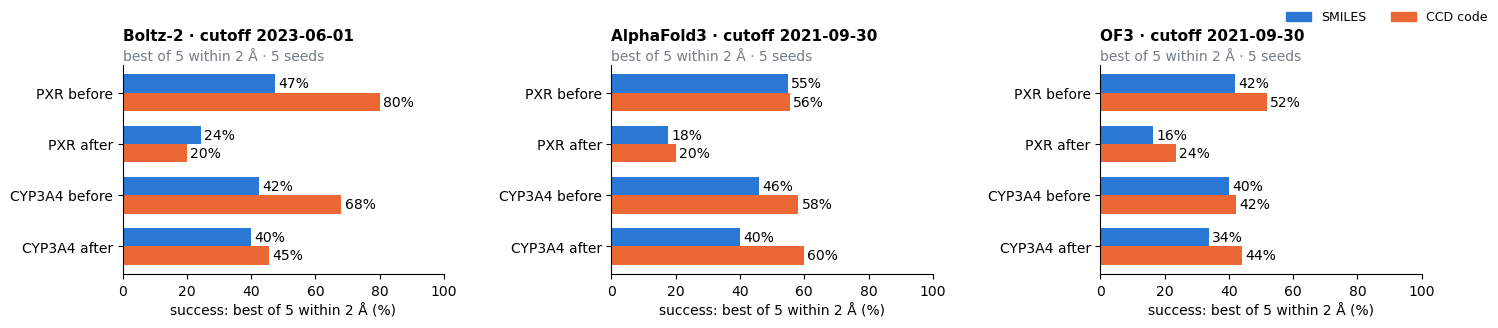

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.3), sharex=True)
for ax, m in zip(axes, CUT_NOTE):
    rows = [(f"{t} {side}", v["smiles"], v["ccd"]) for (t, side), v in G[m].items()]
    C.grouped_bars(ax, rows, f"{C.LABEL[m]} · cutoff {CUT_NOTE[m]}", "best of 5 within 2 Å · 5 seeds")
fig.legend([plt.Rectangle((0, 0), 1, 1, color=C.SMILES), plt.Rectangle((0, 0), 1, 1, color=C.CCD)], ["SMILES", "CCD code"],
           loc="upper right", ncol=2, frameon=False, fontsize=9)
fig.tight_layout(rect=(0, 0, 0.97, 0.97), w_pad=3)
fig.savefig(C.FIGS / "fig4_cutoff_split.png", dpi=160, bbox_inches="tight")
plt.show()